# Joint financial uncertainty

**Two assets that crash together are riskier than two that crash separately, even if each one looks exactly the same on its own.** Hold both, and a forecast that misses the link between them will tell you the pair is safer than it is.

Intervals, quantiles and scores computed one series at a time can't see this, so a forecast can get every series right and still lose the link. In this notebook we forecast four kinds of linked series, break the link on purpose while leaving each series untouched, and see which scores notice.

In [1]:
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from timegym import Scenario, Pipeline, GaussianAR1Forecaster, TestReport, metrics
from timegym.diagnostics import covariance_dependence_check

BLUE, GRAY = '#0000CC', '#808080'
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Four ways for two series to move together

Each scenario generates two series, `y0` and `y1`, linked in a different way:

- **Trend, cycle and jumps** (`composite`): each series has its own trend and cycle; their everyday shocks are correlated (0.7), and jumps hit both at the same moments.
- **Jumping log prices** (Merton jump diffusion): both prices wiggle together (correlation 0.8) and jump at the same moments, with jump sizes correlated at 0.9.
- **Calm and stormy returns** (CCC-GARCH): each series has its own calm and stormy periods, and their shocks keep a fixed correlation of 0.8 (constant conditional correlation).
- **Hidden-regime returns** (Markov switching): one hidden switch drives both, loosely linked (0.3) in the calm regime and tightly (0.9) in the stormy one.

As a first look we fit a Gaussian AR(1) (mean reversion: shocks fade) to 192 steps of history and forecast 12.

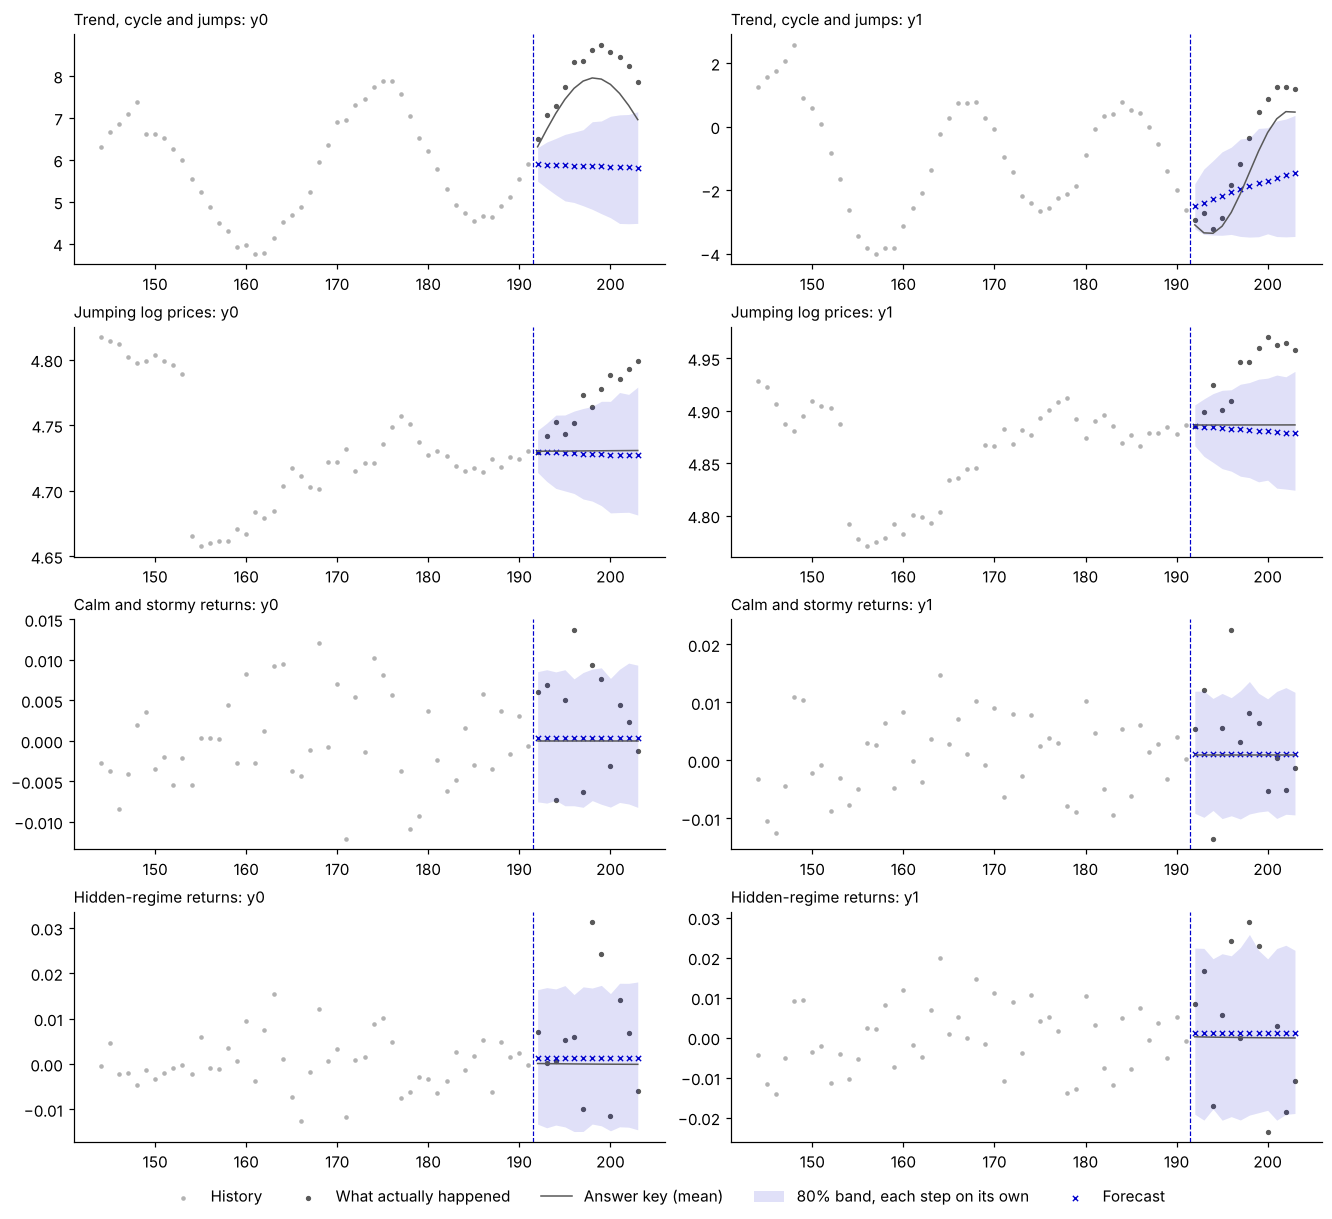

In [2]:
# One number applies to both series; a list gives one value per series; regime settings
# have one entry per regime.
joint_specs = [
    {'kind': 'composite', 'parameters': {'slope': [.02, -.01], 'amplitude': [1.5, 2.],
        'period': [24., 18.], 'sigma': [.15, .25], 'residual': 'random_walk',
        'correlation': .7, 'jump_rate': .035, 'jump_mean': [.1, -.1],
        'jump_sigma': [.4, .6], 'jump_correlation': .8}},
    {'kind': 'merton_jump_diffusion', 'parameters': {'mu': [.04, .07], 'sigma': [.15, .22],
        'correlation': .8, 'jump_rate': 4., 'jump_mean': [-.04, -.08],
        'jump_sigma': [.08, .13], 'jump_correlation': .9, 'output': 'log_price'}},
    {'kind': 'garch', 'parameters': {'mu': [0., .001], 'omega': [3e-6, 8e-6],
        'alpha': [.12, .18], 'beta': [.82, .72], 'correlation': .8, 'output': 'log_return'}},
    {'kind': 'markov_switching', 'parameters': {'regime_mu': [[.04, .08], [-.15, -.2]],
        'regime_sigma': [[.1, .15], [.4, .55]],
        'regime_correlation': [[[1., .3], [.3, 1.]], [[1., .9], [.9, 1.]]],
        'output': 'log_return'}},
]
labels = ['Trend, cycle and jumps', 'Jumping log prices', 'Calm and stormy returns', 'Hidden-regime returns']
scenarios = [Scenario(context_length=192, horizon=12, n_targets=2, **spec) for spec in joint_specs]
fitted = Pipeline(GaussianAR1Forecaster(n_samples=512, seed=71)).run(scenarios, seeds=[11])

fig, axes = plt.subplots(4, 2, figsize=(12, 11), layout='constrained')
for row, (label, entry) in enumerate(zip(labels, fitted.cases)):
    case, forecast = entry.case, entry.forecast
    for j, target in enumerate(case.task.target_names):
        ax, history = axes[row, j], case.task.context.iloc[-48:, j]
        ax.scatter(history.index, history, s=4, color='0.7', label='History')
        ax.scatter(case.observed.index, case.observed.iloc[:, j], s=6, color='0.35',
                   label='What actually happened')
        ax.plot(case.reference.index, case.reference.mean[:, j], color='0.35', linewidth=1,
                label='Answer key (mean)')
        ax.fill_between(forecast.index, forecast.quantiles[:, j, 0], forecast.quantiles[:, j, -1],
                        color=BLUE, alpha=0.12, linewidth=0, label='80% band, each step on its own')
        ax.scatter(forecast.index, forecast.point[:, j], marker='x', s=12, linewidths=0.9,
                   color=BLUE, label='Forecast')
        ax.axvline(case.task.future_index[0] - 0.5, color=BLUE, linestyle='--', linewidth=0.8)
        ax.set_title(f'{label}: {target}', fontsize=10)
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='outside lower center', ncol=5)
plt.show()

The shaded bands are 80% bands for each step on its own, not a band the whole path stays inside 80% of the time. The AR(1) is a simple baseline: it can't follow the cycles in the first row, so the answer key drifts out of its band there.

Now look at the jumping log prices in the second row. At step 154 both series drop at once: a shared jump. After the forecast starts, both climb above their bands together. Two separate bands can't tell you how likely that was, and neither could two perfect ones. To study the link alone, we need a forecast that gets each series exactly right, and then we break only the link.

## Keep each series, shuffle the partners

The answer key can draw possible futures from the true process. We take 768 per scenario; each draw is a pair of six-step paths, one for `y0` and one for `y1`, that belong together. No forecast could do better.

Then we inject a bug: we shuffle the `y1` paths among the draws, so each `y0` path gets a random partner. Every path survives intact, so each series on its own is exactly as before; only the pairing is gone. Bugs like this happen when two series are simulated or resampled separately and then zipped together.

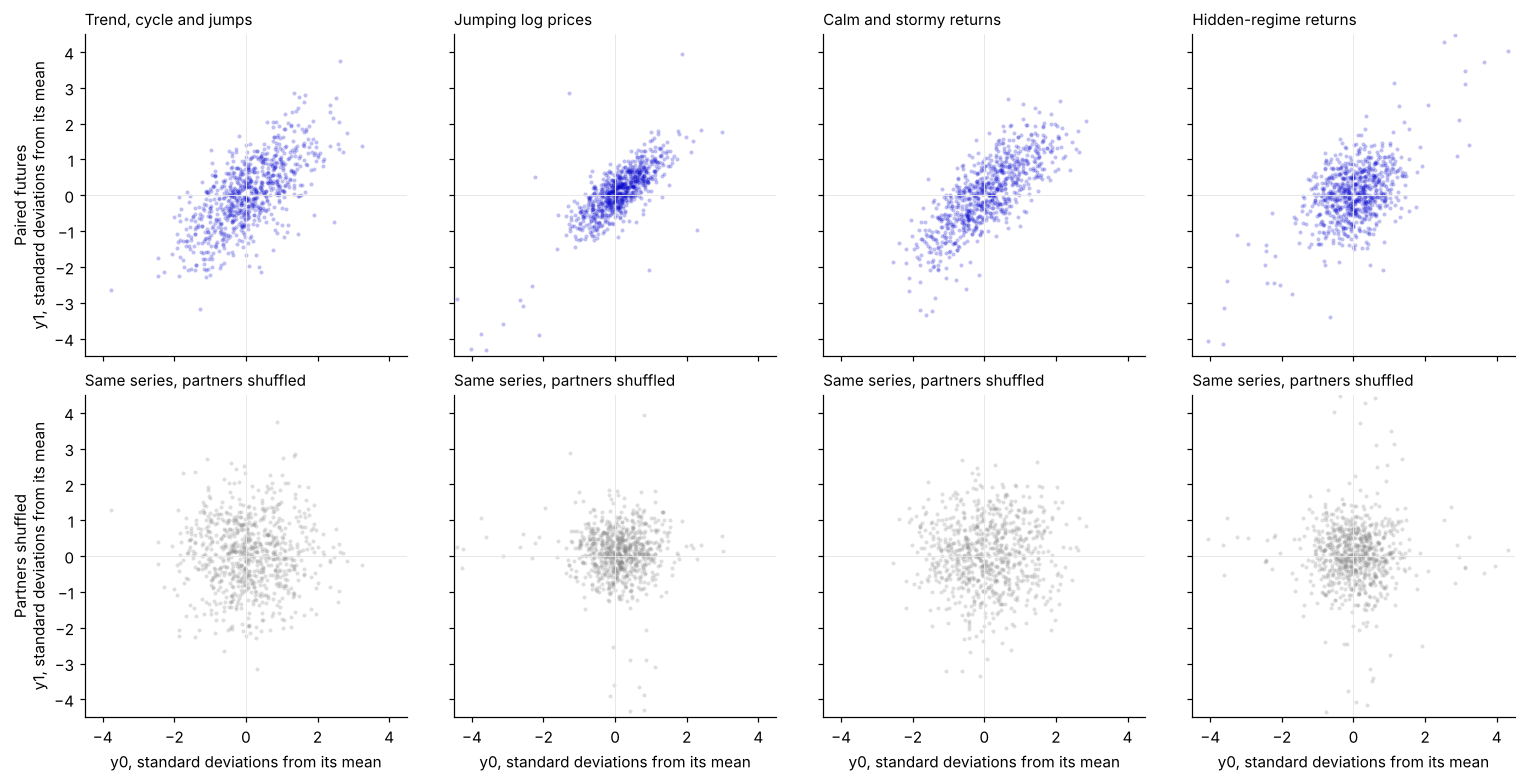

In [3]:
cases = [Scenario(context_length=192, horizon=6, n_targets=2, **spec).generate(seed=11)
         for spec in joint_specs]
clean = [case.reference.forecast(n_samples=768, seed=91) for case in cases]
permutation = np.random.default_rng(18).permutation(768)
broken = []
for forecast in clean:
    shuffled = deepcopy(forecast)
    shuffled.samples[:, :, 1] = forecast.samples[permutation, :, 1]
    # Each series on its own is untouched: the same values at every step.
    np.testing.assert_array_equal(np.sort(shuffled.samples, axis=0), np.sort(forecast.samples, axis=0))
    broken.append(shuffled)

H = 3  # look at the fourth step ahead
fig, axes = plt.subplots(2, 4, figsize=(14, 7), layout='constrained', sharex=True, sharey=True)
for col, (label, case, original, shuffled) in enumerate(zip(labels, cases, clean, broken)):
    for row, (name, forecast, color) in enumerate([('Paired futures', original, BLUE),
                                                  ('Partners shuffled', shuffled, GRAY)]):
        surprise = (forecast.samples[:, H] - case.reference.mean[H]) / np.sqrt(case.reference.variance[H])
        ax = axes[row, col]
        ax.scatter(surprise[:, 0], surprise[:, 1], s=7, color=color, alpha=.25, linewidths=0)
        ax.axhline(0, color='0.9', lw=.6); ax.axvline(0, color='0.9', lw=.6)
        ax.set(xlim=(-4.5, 4.5), ylim=(-4.5, 4.5), aspect='equal')
        ax.set_title(label if row == 0 else 'Same series, partners shuffled', fontsize=10)
        if col == 0:
            ax.set_ylabel(f'{name}\ny1, standard deviations from its mean')
        if row == 1:
            ax.set_xlabel('y0, standard deviations from its mean')
plt.show()

Each dot is one possible future, four steps ahead. In the top row the clouds lean: when `y0` is low, `y1` tends to be low too. For the jumping log prices and the hidden regimes, a few dots sit far out in the bottom-left corner, where both series crash at once. In the bottom row the clouds are round, and the extreme dots have moved out along the axes: one series crashes while the other carries on.

## Crashing together is the risk

How much does the lost link matter? The heat maps show, for the jumping log prices, how strongly each pair of forecast values moves together, across both series and all six steps. The table then measures joint risk in all four scenarios, four steps ahead:

- **Both crash**: how often both series land in their own worst 5% at the same time. Independent series would do so in about 0.25% of futures (5% of 5%).
- **Spread**: measure each series' surprise in its own standard deviations, average the two, and take the spread of that average. Think of it as the risk of holding both equally.

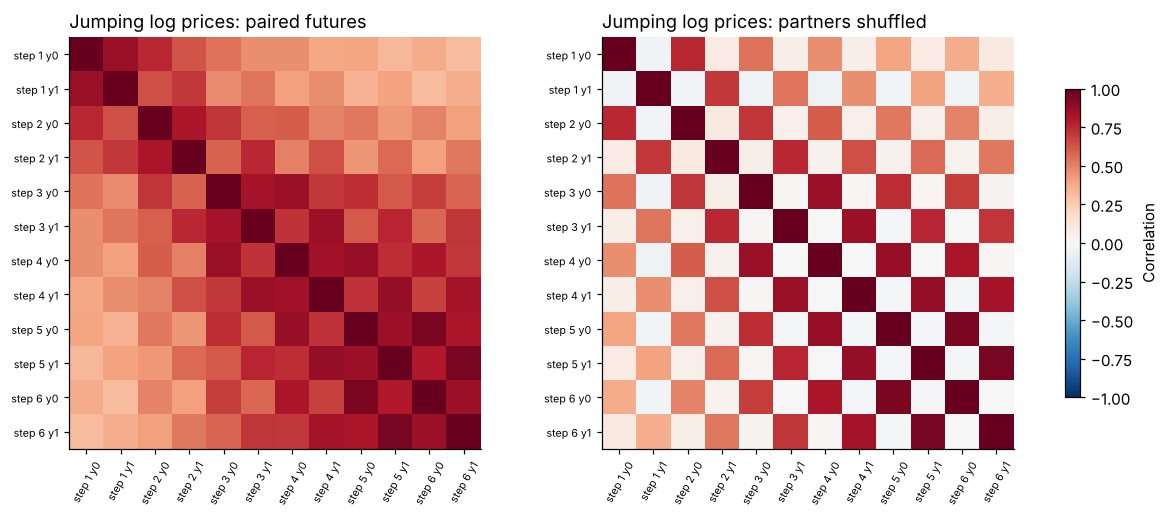

,"both crash, paired","both crash, shuffled","spread, paired","spread, shuffled"
scenario,,,,
"Trend, cycle and jumps",1.4%,0.4%,0.89,0.70
Jumping log prices,3.0%,0.1%,0.91,0.67
Calm and stormy returns,2.0%,0.0%,0.91,0.69
Hidden-regime returns,2.6%,0.5%,0.87,0.69


In [4]:
case, original, shuffled = cases[1], clean[1], broken[1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout='constrained')
coordinate_labels = [f'step {h + 1} {target}' for h in range(6) for target in case.task.target_names]
for ax, title, forecast in zip(axes, ['Paired futures', 'Partners shuffled'], [original, shuffled]):
    correlation = np.corrcoef(forecast.samples.reshape(768, -1), rowvar=False)
    im = ax.imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_title(f'Jumping log prices: {title.lower()}')
    ax.set_xticks(range(12), coordinate_labels, rotation=60, fontsize=7)
    ax.set_yticks(range(12), coordinate_labels, fontsize=7)
fig.colorbar(im, ax=list(axes), shrink=.75, label='Correlation')
plt.show()


def joint_risk(case, forecast):
    draws = forecast.samples[:, H]
    surprise = (draws - case.reference.mean[H]) / np.sqrt(case.reference.variance[H])
    both_crash = (draws <= np.quantile(draws, 0.05, axis=0)).all(axis=1).mean()
    return both_crash, surprise.mean(axis=1).std(ddof=1)


rows = []
for label, case, original, shuffled in zip(labels, cases, clean, broken):
    (paired_crash, paired_spread), (shuffled_crash, shuffled_spread) = (
        joint_risk(case, original), joint_risk(case, shuffled))
    assert paired_crash > 2 * shuffled_crash and paired_spread > shuffled_spread  # the shuffle hides joint risk
    rows.append({'scenario': label,
                 'both crash, paired': f'{paired_crash:.1%}', 'both crash, shuffled': f'{shuffled_crash:.1%}',
                 'spread, paired': round(paired_spread, 2), 'spread, shuffled': round(shuffled_spread, 2)})
display(pd.DataFrame(rows).set_index('scenario'))

In the paired heat map every square is red or pink. After the shuffle a checkerboard appears: squares that pair a series with itself keep their color, because each path survived intact, while squares that pair `y0` with `y1` fade to nearly white.

In the table, both series crash together in 1.4% to 3.0% of the paired futures, but in only 0% to 0.5% once partners are shuffled, close to the 0.25% of independent series. The spread falls by a fifth to a quarter, from about 0.9 to 0.7. A forecast with this bug would tell you that holding both is safer than it is.

## Which scores notice?

We score both versions against what actually happened, with one per-series score (CRPS) and two joint scores that look at both series and all steps together (energy and variogram scores; lower is better for all three). Then we run the covariance check (`covariance_dependence_check`, reported as `reference_covariance`). It compares how the forecast's draws vary together with how the answer key's do: it draws 39 fresh sets of futures from the answer key and asks how often they are as far from the true pattern as the forecast. A small p-value means "rarely": the forecast's links are wrong.

In [5]:
rows = []
for label, case, original, shuffled in zip(labels, cases, clean, broken):
    observed = case.observed.to_numpy()
    for name, forecast, expected in [('paired', original, 'PASS'), ('shuffled', shuffled, 'FAIL')]:
        check = covariance_dependence_check(case.reference, forecast.samples, seed=741, n_calibration=39)
        assert check.status == expected  # the check fails every shuffled forecast and no paired one
        rows.append({'scenario': label, 'forecast': name,
                     'per-series score (CRPS)': metrics.crps(observed, forecast.samples),
                     'energy score': metrics.energy_score(observed, forecast.samples),
                     'variogram score': metrics.variogram_score(observed, forecast.samples),
                     'covariance check': check.status, 'p-value': check.evidence['p_value']})
summary = pd.DataFrame(rows).set_index(['scenario', 'forecast'])
crps = summary['per-series score (CRPS)'].unstack()
np.testing.assert_allclose(crps['paired'], crps['shuffled'], rtol=0, atol=1e-13)  # CRPS is blind to the shuffle
display(summary.round(5))

per-series score (CRPS)  energy score  \
scenario                forecast                                          
Trend, cycle and jumps  paired                    0.27173       1.12776   
                        shuffled                  0.27173       1.15410   
Jumping log prices      paired                    0.01260       0.05519   
                        shuffled                  0.01260       0.05739   
Calm and stormy returns paired                    0.00621       0.02616   
                        shuffled                  0.00621       0.02623   
Hidden-regime returns   paired                    0.00613       0.02725   
                        shuffled                  0.00613       0.02717   

                                  variogram score covariance check  p-value  
scenario                forecast                                             
Trend, cycle and jumps  paired            0.02353             PASS    0.275  
                        shuffled          0.02351             FAIL    0.025  
Jumping log prices      paired            0.00175             PASS    0.575  
                        shuffled          0.00175             FAIL    0.025  
Calm and stormy returns paired            0.00227             PASS    0.700  
                        shuffled          0.00225             FAIL    0.025  
Hidden-regime returns   paired            0.00191             PASS    0.825  
                        shuffled          0.00189             FAIL    0.025

The per-series score is identical for the paired and shuffled forecasts: it cannot see the shuffle. The joint scores barely move, and not always the right way. The energy score is worse for the shuffled forecast in three scenarios out of four, by at most 4%, and the variogram score comes out slightly better for it in all four. They judge the single future that happened, and one future says little about how two series move together.

The covariance check compares whole sets of futures instead. It passes all four paired forecasts and fails all four shuffled ones, each with p = 0.025: none of the 39 answer-key sets was as far off, and 1 in 40 is the smallest p-value 39 sets can give.

Now repair the bug by undoing the shuffle, and run the same check again.

In [6]:
for label, case, original, shuffled in zip(labels, cases, clean, broken):
    repaired = deepcopy(shuffled)
    repaired.samples[:, :, 1] = shuffled.samples[np.argsort(permutation), :, 1]
    before = covariance_dependence_check(case.reference, original.samples, seed=741, n_calibration=39)
    after = covariance_dependence_check(case.reference, repaired.samples, seed=741, n_calibration=39)
    assert (after.status, after.evidence['p_value']) == (before.status, before.evidence['p_value'])
    print(f"{label}: {after.status} after the repair (p = {after.evidence['p_value']:.3f}), "
          f"the same as the original forecast")

Trend, cycle and jumps: PASS after the repair (p = 0.275), the same as the original forecast
Jumping log prices: PASS after the repair (p = 0.575), the same as the original forecast
Calm and stormy returns: PASS after the repair (p = 0.700), the same as the original forecast
Hidden-regime returns: PASS after the repair (p = 0.825), the same as the original forecast


The check is seeded, so the repaired forecast gets exactly the original verdict.

## How far to trust the answer key

The covariance check is only as good as its answer key, so TimeGym records how each answer key was made. The table lists the four scenarios plus a fifth: the hidden regimes again, with jumps that depend on the regime (rare small jumps when calm, frequent large ones when stormy).

The first four use exact formulas (`analytic`) and draw futures from the true process (`exact_conditional`). The calm and stormy returns add one numerical estimate: the covariance between the two series comes from simulation (16,384 draws) and is held fixed while the check runs.

The fifth is different. To work out the regime, the answer key must count how many jumps might have happened at each step, and it stops counting at some point (a truncated Poisson mixture). Its draws are approximate (`approximate_conditional`), and an exact test against an approximate answer key would mean nothing, so the covariance check returns **UNSUPPORTED**: not checked. Scores and samples still work.

In [7]:
jump_settings = {**joint_specs[3]['parameters'],
                 'regime_jump_rate': [2., 12.],
                 'regime_jump_mean': [[-.02, -.03], [-.08, -.12]],
                 'regime_jump_sigma': [[.02, .04], [.08, .12]],
                 'jump_correlation': .8}
jump_case = Scenario('markov_switching', 192, 6, jump_settings, n_targets=2).generate(seed=11)
trust = pd.DataFrame([{'scenario': label, **case.reference.capabilities}
                      for label, case in zip(labels + ['Hidden regimes + jumps'], cases + [jump_case])])
display(trust.set_index('scenario')[['moments_kind', 'covariance_kind', 'moment_samples', 'sampler_kind']]
        .astype(object).fillna(''))

jump_forecast = jump_case.reference.forecast(256, seed=91)
check = covariance_dependence_check(jump_case.reference, jump_forecast.samples)
assert check.status == 'UNSUPPORTED'  # no exact test against an approximate answer key
print(f'{check.status}: {check.message}')

conditioning = jump_case.reference.conditioning
calm, stormy = conditioning['state_posterior']
print(f'Regime worked out from both series\' history: calm {calm:.1%}, stormy {stormy:.1%}. '
      f'True hidden state shown to the model: {conditioning["hidden_states_exposed_to_model"]}. '
      f'Probability left out by the cut-off (emission_poisson_tail_bound): {conditioning["emission_poisson_tail_bound"]:.1g}.')

,moments_kind,covariance_kind,moment_samples,sampler_kind
scenario,,,,
"Trend, cycle and jumps",analytic,,,exact_conditional
Jumping log prices,analytic,,,exact_conditional
Calm and stormy returns,analytic_mean_monte_carlo_covariance,monte_carlo,16384.0,exact_conditional
Hidden-regime returns,analytic,,,exact_conditional
Hidden regimes + jumps,analytic,,,approximate_conditional


UNSUPPORTED: An approximate reference simulator cannot calibrate an exact conditional-law diagnostic.
Regime worked out from both series' history: calm 99.5%, stormy 0.5%. True hidden state shown to the model: False. Probability left out by the cut-off (emission_poisson_tail_bound): 3e-13.


The answer key works out the regime from both series together and never sees the true state, just as a real forecaster couldn't. The probability left out by the cut-off, about 3e-13 here, only measures how much of the jump count was dropped. It is not a bound on how wrong the regime probabilities are, which is why the answer key counts as approximate however small it is.

## Replay a case months later

The fitted AR(1) run from the start saved everything needed to rebuild a case: the generator and its links, the fitted model and the answer key's numerical settings. We save the report as JSON, load it back and replay the calm and stormy returns.

In [8]:
loaded = TestReport.from_json(fitted.report.to_json())
replay = loaded.replay_case(2)  # calm and stormy returns (CCC-GARCH)
outcome = replay.metadata['replay']
assert outcome['manifest_match'] and outcome['metrics_match'] and outcome['diagnostics_match']
print(f"Replayed {replay.cases[0].scenario}, seed {replay.cases[0].seed}: settings match {outcome['manifest_match']}, "
      f"scores match {outcome['metrics_match']}, checks match {outcome['diagnostics_match']}.")

Replayed garch, seed 11: settings match True, scores match True, checks match True.


## Change one thing

- Make `correlation` negative, so one series tends to rise when the other falls.
- Set the shock correlation to 0 (`correlation`, or identity matrices for `regime_correlation`). Shared jumps and the shared hidden regime still tie the series together.
- Set the jump rate to 0, or make the two regimes identical, and see which links remain.

Change one setting at a time. Regime filtering needs positive volatilities and a valid (positive-definite) correlation matrix in every regime.

**What this doesn't show.** These are software demonstrations, not estimates of financial risk: the average surprise stands in for a portfolio but is not a portfolio return. A correct forecast still fails the covariance check about 5% of the time, and one seed per scenario doesn't measure how often the check catches a bug. We broke only the pairing; we didn't test faults inside one series, such as missing jumps, or run the check on a fitted model's draws.

This is the last tutorial. **Next:** [the tutorials overview](../docs/notebooks.md).